<a href="https://colab.research.google.com/github/sambhavi298/cart/blob/main/cart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DATASET INFORMATION
-------------------
Dataset Shape: (569, 30)
Number of Features: 30
Number of Samples: 569
Target Classes: ['malignant' 'benign']

First Five Rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   


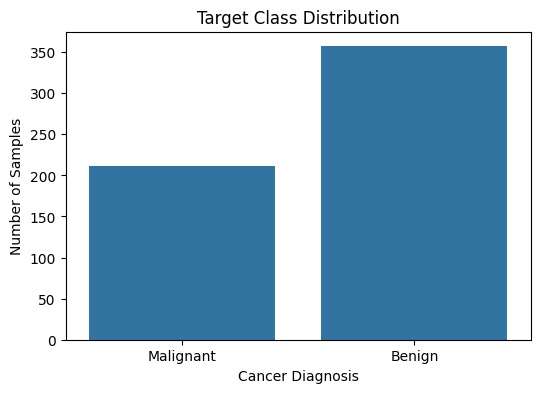


INPUT FEATURES:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

TARGET VARIABLE:
Target: Cancer Diagnosis
0 = Malignant
1 = Benign

TRAIN-TEST SPLIT
----------------
Training Samples: 455
Testing Samples: 114

CART MODEL TRAINED SUCCESSFULLY

MAX_DEPTH COMPARISON:
Max Depth  Training Accuracy  Testing Accuracy
        1           0.923077          0.921053
        2           0.958242          0.894737
        3           0.975824          0.938596
        4        

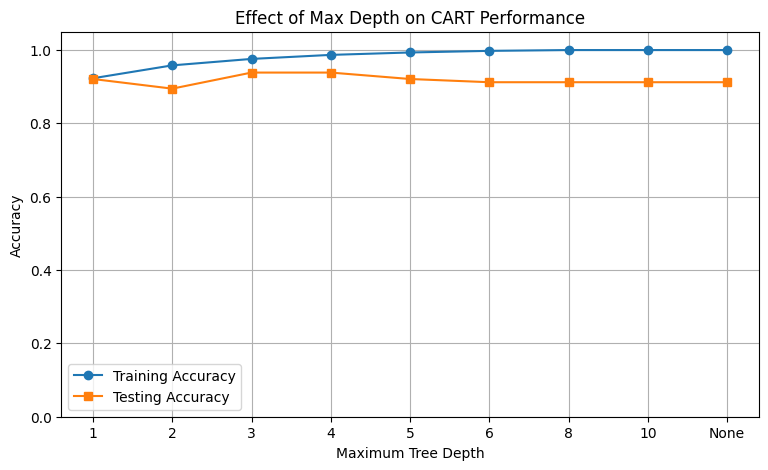


MIN_SAMPLES_SPLIT COMPARISON:
 Min Samples Split  Testing Accuracy
                 2          0.938596
                 5          0.938596
                10          0.929825
                20          0.938596

MIN_SAMPLES_LEAF COMPARISON:
 Min Samples Leaf  Testing Accuracy
                1          0.938596
                2          0.929825
                5          0.921053
               10          0.947368


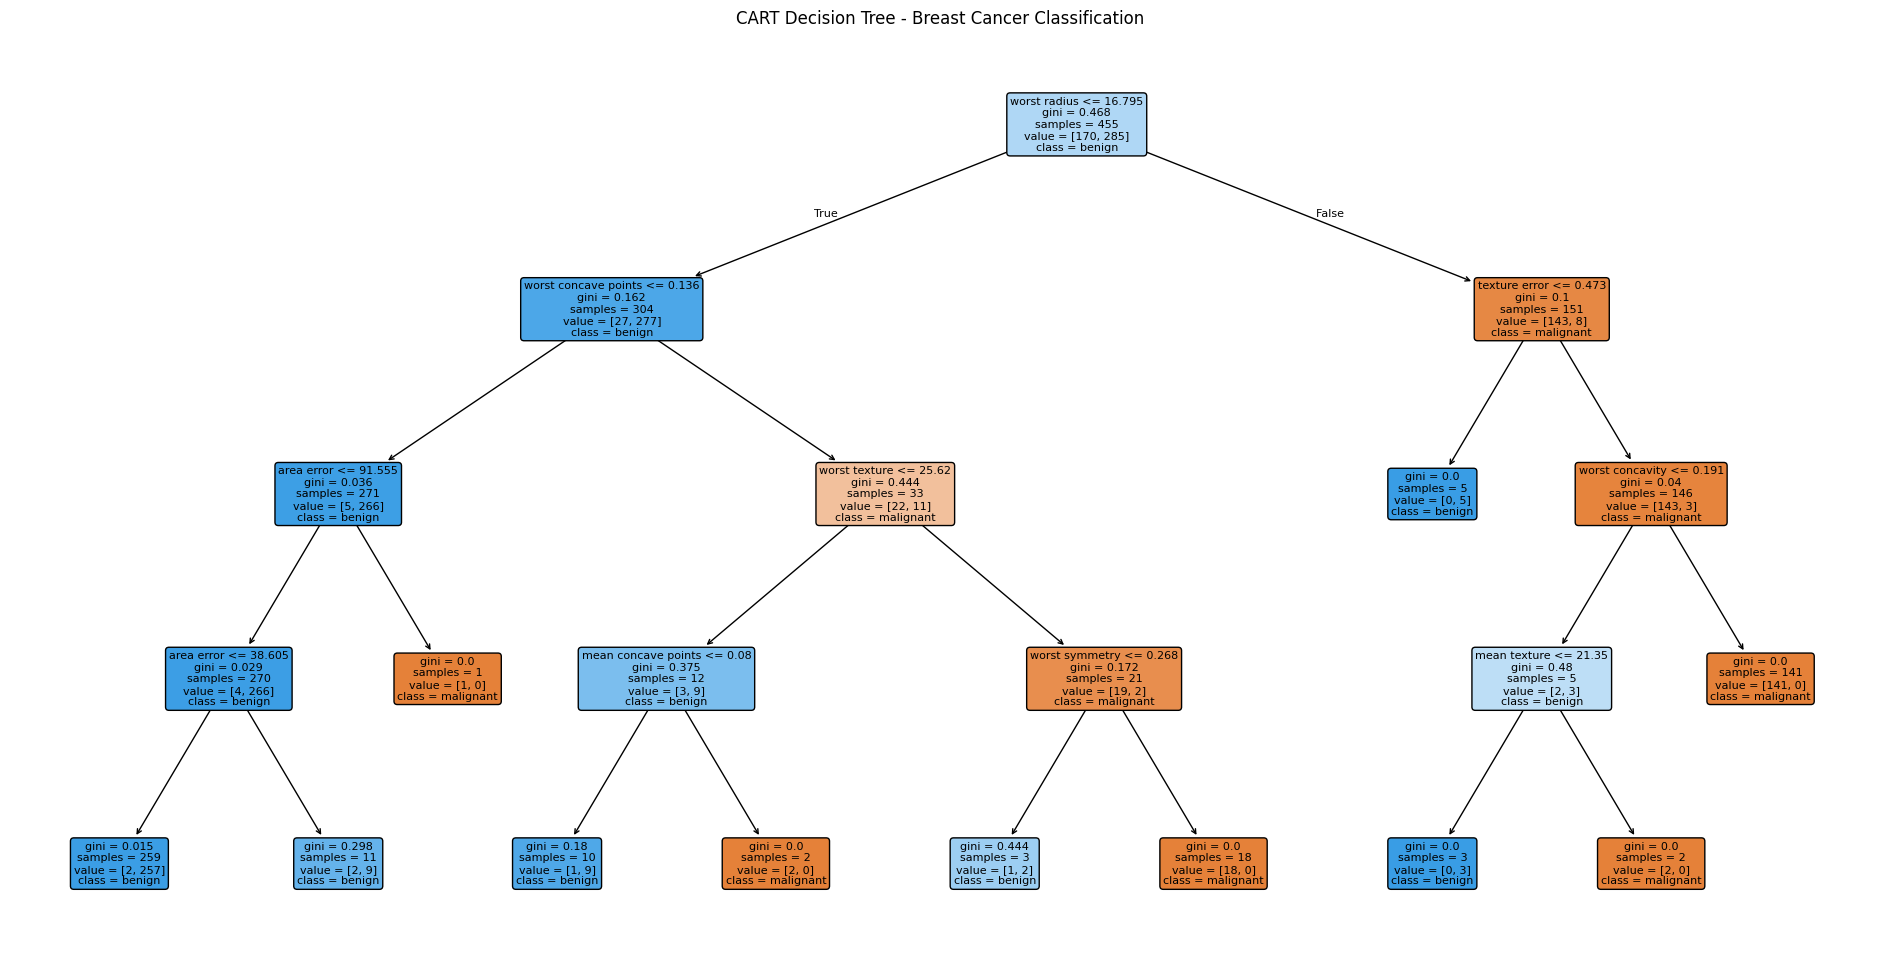


TREE DEPTH: 4
NUMBER OF LEAF NODES: 11

ACTUAL VS PREDICTED RESULTS:
 Actual Class  Predicted Class Actual Diagnosis Predicted Diagnosis
            0                0        Malignant           Malignant
            1                1           Benign              Benign
            0                0        Malignant           Malignant
            1                1           Benign              Benign
            0                0        Malignant           Malignant
            1                1           Benign              Benign
            1                1           Benign              Benign
            0                0        Malignant           Malignant
            0                0        Malignant           Malignant
            0                0        Malignant           Malignant
            1                1           Benign              Benign
            0                0        Malignant           Malignant
            1                1           Benig

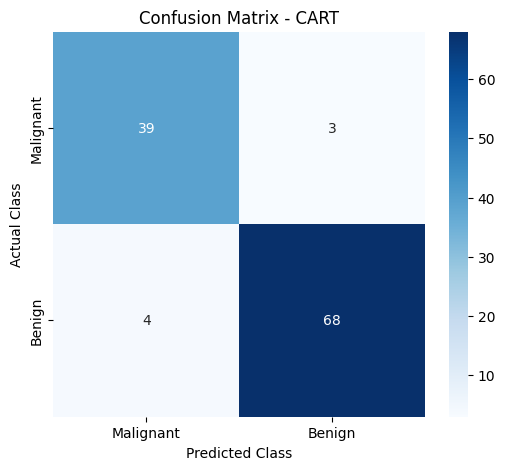


CONFUSION MATRIX:
[[39  3]
 [ 4 68]]

FINAL PERFORMANCE TABLE:
   Metric    Score
 Accuracy 0.938596
Precision 0.906977
   Recall 0.928571
 F1 Score 0.917647

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

   malignant       0.91      0.93      0.92        42
      benign       0.96      0.94      0.95        72

    accuracy                           0.94       114
   macro avg       0.93      0.94      0.93       114
weighted avg       0.94      0.94      0.94       114


FINAL INFERENCE
----------------
1. CART was successfully implemented using the Breast Cancer dataset.
2. The decision tree uses Gini Impurity to select the best splitting feature.
3. Changing max_depth affects tree complexity and model performance.
4. A very small depth may cause underfitting.
5. A very large depth may cause overfitting.
6. min_samples_split and min_samples_leaf control tree growth.
7. The model was evaluated using Accuracy, Precision, Recall, F1 Score, and Confusion

In [ ]:

# ============================================================
# EXPERIMENT: IMPLEMENTATION AND PERFORMANCE EVALUATION OF CART
# Dataset: Breast Cancer Wisconsin Dataset
# ============================================================

# 1. IMPORT REQUIRED LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ============================================================
# 2. LOAD THE DATASET
# ============================================================

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="Target")

print("DATASET INFORMATION")
print("-------------------")
print("Dataset Shape:", X.shape)
print("Number of Features:", X.shape[1])
print("Number of Samples:", X.shape[0])
print("Target Classes:", data.target_names)

print("\nFirst Five Rows:")
print(X.head())

# ============================================================
# 3. EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

print("\nDATASET INFORMATION:")
X.info()

print("\nSTATISTICAL SUMMARY:")
print(X.describe())

print("\nMISSING VALUES:")
print(X.isnull().sum().sum())

print("\nDUPLICATE ROWS:")
print(X.duplicated().sum())

print("\nTARGET CLASS DISTRIBUTION:")
print(y.value_counts())

# Target class distribution graph

plt.figure(figsize=(6, 4))
sns.countplot(x=y.map({0: "Malignant", 1: "Benign"}))
plt.title("Target Class Distribution")
plt.xlabel("Cancer Diagnosis")
plt.ylabel("Number of Samples")
plt.show()

# ============================================================
# 4. IDENTIFY INPUT FEATURES AND TARGET
# ============================================================

print("\nINPUT FEATURES:")
print(list(X.columns))

print("\nTARGET VARIABLE:")
print("Target: Cancer Diagnosis")
print("0 = Malignant")
print("1 = Benign")

# ============================================================
# 5. PREPROCESSING AND TRAIN-TEST SPLIT
# ============================================================

# No feature scaling is required for decision trees.
# The dataset does not contain missing values.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTRAIN-TEST SPLIT")
print("----------------")
print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

# ============================================================
# 6. IMPLEMENT CART CLASSIFIER
# ============================================================

cart_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42
)

cart_model.fit(X_train, y_train)

# Predict test data

y_pred = cart_model.predict(X_test)

print("\nCART MODEL TRAINED SUCCESSFULLY")

# ============================================================
# 7. EXPERIMENT WITH DIFFERENT MAX_DEPTH VALUES
# ============================================================

depth_values = [1, 2, 3, 4, 5, 6, 8, 10, None]

depth_results = []

for depth in depth_values:

    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        random_state=42
    )

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_accuracy = accuracy_score(y_train, train_pred)
    test_accuracy = accuracy_score(y_test, test_pred)

    depth_results.append({
        "Max Depth": str(depth),
        "Training Accuracy": train_accuracy,
        "Testing Accuracy": test_accuracy
    })

depth_df = pd.DataFrame(depth_results)

print("\nMAX_DEPTH COMPARISON:")
print(depth_df.to_string(index=False))

# Plot training and testing accuracy

plt.figure(figsize=(9, 5))

plt.plot(
    depth_df["Max Depth"],
    depth_df["Training Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    depth_df["Max Depth"],
    depth_df["Testing Accuracy"],
    marker="s",
    label="Testing Accuracy"
)

plt.title("Effect of Max Depth on CART Performance")
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.legend()
plt.grid(True)
plt.show()

# ============================================================
# 8. EXPERIMENT WITH min_samples_split
# ============================================================

split_values = [2, 5, 10, 20]
split_results = []

for value in split_values:

    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        min_samples_split=value,
        random_state=42
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    split_results.append({
        "Min Samples Split": value,
        "Testing Accuracy": accuracy_score(y_test, predictions)
    })

split_df = pd.DataFrame(split_results)

print("\nMIN_SAMPLES_SPLIT COMPARISON:")
print(split_df.to_string(index=False))

# ============================================================
# 9. EXPERIMENT WITH min_samples_leaf
# ============================================================

leaf_values = [1, 2, 5, 10]
leaf_results = []

for value in leaf_values:

    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        min_samples_leaf=value,
        random_state=42
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    leaf_results.append({
        "Min Samples Leaf": value,
        "Testing Accuracy": accuracy_score(y_test, predictions)
    })

leaf_df = pd.DataFrame(leaf_results)

print("\nMIN_SAMPLES_LEAF COMPARISON:")
print(leaf_df.to_string(index=False))

# ============================================================
# 10. VISUALIZE THE DECISION TREE
# ============================================================

plt.figure(figsize=(24, 12))

plot_tree(
    cart_model,
    feature_names=data.feature_names,
    class_names=data.target_names,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("CART Decision Tree - Breast Cancer Classification")
plt.show()

print("\nTREE DEPTH:", cart_model.get_depth())
print("NUMBER OF LEAF NODES:", cart_model.get_n_leaves())

# ============================================================
# 11. DISPLAY PREDICTED AND ACTUAL CLASSES
# ============================================================

prediction_results = pd.DataFrame({
    "Actual Class": y_test.values,
    "Predicted Class": y_pred
})

prediction_results["Actual Diagnosis"] = prediction_results[
    "Actual Class"
].map({0: "Malignant", 1: "Benign"})

prediction_results["Predicted Diagnosis"] = prediction_results[
    "Predicted Class"
].map({0: "Malignant", 1: "Benign"})

print("\nACTUAL VS PREDICTED RESULTS:")
print(prediction_results.head(20).to_string(index=False))

# ============================================================
# 12. EVALUATE MODEL PERFORMANCE
# ============================================================

# Treat Malignant (class 0) as the positive class.

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    pos_label=0,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label=0,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label=0,
    zero_division=0
)

print("\nCART PERFORMANCE METRICS")
print("------------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

# ============================================================
# 13. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.title("Confusion Matrix - CART")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()

print("\nCONFUSION MATRIX:")
print(cm)

# ============================================================
# 14. PERFORMANCE METRICS TABLE
# ============================================================

metrics_table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Score": [accuracy, precision, recall, f1]
})

print("\nFINAL PERFORMANCE TABLE:")
print(metrics_table.to_string(index=False))

# ============================================================
# 15. CLASSIFICATION REPORT
# ============================================================

print("\nCLASSIFICATION REPORT:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=data.target_names,
        zero_division=0
    )
)

# ============================================================
# 16. FINAL INFERENCE
# ============================================================

print("\nFINAL INFERENCE")
print("----------------")

print("1. CART was successfully implemented using the Breast Cancer dataset.")

print("2. The decision tree uses Gini Impurity to select the best splitting feature.")

print("3. Changing max_depth affects tree complexity and model performance.")

print("4. A very small depth may cause underfitting.")

print("5. A very large depth may cause overfitting.")

print("6. min_samples_split and min_samples_leaf control tree growth.")

print("7. The model was evaluated using Accuracy, Precision, Recall, F1 Score, and Confusion Matrix.")

print("\nExperiment Completed Successfully.")
